# EcoSort — Treinamento v2.2.0 (YOLOv8n-cls + Dataset Público + Fine-Tuning de Borda)

Treina o classificador partindo do backbone **YOLOv8n-cls** (`yolov8n-cls.pt`) para máxima estabilidade no runtime NCNN da Raspberry Pi 4 (sem o bloco `C2PSA`), utilizando **Transfer Learning em Duas Fases Reais (Domínio Público -> Domínio da Lixeira)**.

Blocos: **1** Imports/Config · **2** Filtro do Dataset da Borda (exclui crops quadrados antigos) + Split 70/15/15 · **2.5** Download e Preparo do Dataset Público (Kaggle 12-classes filtrado para as 7 oficiais) · **3** Augmentation Direcionada (mín. 150 imgs/classe no Train da Borda) · **4** Config do Modelo · **5** Fase 1 (Pré-treino de Geometria/Textura no Dataset Público + Borda) · **6** Fase 2 (Fine-Tuning de Domínio exclusivo na Borda com Backbone Congelado) · **7** Hard Example Mining · **8** Avaliação no Test Isolado da Borda · **9** Export NCNN + Teste de Paridade.

**O que mudou na v2.2.0 para corrigir os erros na Raspberry Pi:**
- **Retorno para `yolov8n-cls.pt`:** O módulo de atenção `C2PSA` do YOLO11 exige versões muito específicas do `ncnn`/`pnnx` no ARM64 e pode gerar previsões corrompidas na borda (`green-glass` / `cardboard`). O YOLOv8 usa convoluções puras (`C2f`), 100% compatíveis com qualquer runtime NCNN.
- **Exclusão automática das 79 fotos quadradas antigas (Bloco 2):** Os recortes 1:1 antigos distorciam o pré-processamento em relação ao frame `1280x720` atual da câmera.
- **Injeção do Dataset Público `mostafaabla/garbage-classification` (Bloco 2.5):** Possui exatamente as mesmas 7 classes oficiais (`plastic`, `metal`, `white-glass`, `brown-glass`, `green-glass`, `paper`, `cardboard`). Na **Fase 1**, o modelo aprende o que é uma lata de metal, uma garrafa PET e vidros coloridos em milhares de fotos reais variadas (combatendo o vício de fundo). Na **Fase 2**, congelamos o extrator de características e refinamos com LR baixo apenas nas fotos da sua lixeira para calibrar a iluminação local sem sofrer *catastrophic forgetting*.
- **Meta mínima de Augmentation (Bloco 3):** Elevada de 39 para **150 imagens por classe** no conjunto de treino da borda.

## Bloco 1 — Imports e Configuração

Centraliza caminhos, as **7 classes oficiais**, o otimizador e a versão do modelo (`v2.2.0`).

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

!pip install split-folders "ultralytics>=8.3.0" scikit-learn kagglehub --quiet

import os, shutil, glob, random
import numpy as np
import cv2
from PIL import Image, ImageEnhance
import ultralytics
from ultralytics import YOLO

# --- Versão e nomes ---
MODELO_VERSAO = 'v2.2.0'
RUN_PREFIX    = 'ecosort_' + MODELO_VERSAO.replace('.', '_')   # ecosort_v2_2_0

# --- Caminhos ---
DATASET_DRIVE = '/content/drive/MyDrive/EcoSort_Datasets/v2.0.0'    # dataset da lixeira (frames inteiros)
BASE_DIR      = '/content/dataset-ecosort-base'                     # só as 7 classes oficiais (sem crops quadrados)
SPLIT_DIR     = '/content/dataset-ecosort-split'                    # train/val/test exclusivo da borda
PRETRAIN_DIR  = '/content/dataset-pretrain-mix'                     # dataset público + train da borda (Fase 1)
PROJECT_DIR   = '/content/drive/MyDrive/EcoSort_Modelos'

# Backbone YOLOv8 (yolov8n-cls.pt) -> 100% estável no NCNN da Raspberry Pi 4
MODELO_BASE   = 'yolov8n-cls.pt'

# --- 7 classes oficiais do sistema ---
CLASSES_OFICIAIS = ['plastic', 'metal', 'white-glass', 'brown-glass', 'green-glass',
                    'paper', 'cardboard']

# --- Parâmetros globais ---
SEED              = 42
IMG_SIZE          = 224        # resolução nativa do YOLOv8n-cls pré-treinado
RATIO             = (0.70, 0.15, 0.15)
OPTIMIZER         = 'AdamW'    # fixo: com 'auto' o Ultralytics ignora o lr0
MAX_PUBLIC_PER_CLS = 400       # máximo de imagens públicas por classe na Fase 1 (equilíbrio + velocidade)
ALVO_AUG_BORDA    = 150        # mínimo de imagens por classe no train da borda (Bloco 3)

random.seed(SEED)
np.random.seed(SEED)

print('Ultralytics', ultralytics.__version__, '| Modelo Base:', MODELO_BASE, '| Classes:', len(CLASSES_OFICIAIS))

Mounted at /content/drive
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 81.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.9/96.9 kB 11.5 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.177 | Modelo Base: yolov8n-cls.pt | Classes: 7


## Bloco 2 — Filtro de classes + Exclusão de Crops Quadrados + Split 70/15/15

A borda (`main.py`) classifica o **frame inteiro** (`1280x720`). As **79 imagens quadradas antigas** (recortes da época em que a borda fazia crop) agora são **automaticamente ignoradas (`continue`)** para não contaminar a proporção geométrica que o modelo enxerga. O split `train/val/test` do seu dataset ocorre antes de qualquer augmentation.

In [ ]:
import splitfolders

# --- Confere classes ---
classes_no_disco = sorted(
    d for d in os.listdir(DATASET_DRIVE)
    if os.path.isdir(os.path.join(DATASET_DRIVE, d)) and not d.startswith('.')
)
faltando = set(CLASSES_OFICIAIS) - set(classes_no_disco)
extra    = set(classes_no_disco) - set(CLASSES_OFICIAIS)
if faltando:
    raise ValueError(f'Faltam classes oficiais no dataset: {sorted(faltando)}')
if extra:
    print(f'Pastas fora das 7 oficiais (NÃO serão copiadas): {sorted(extra)}')

# --- Copia só as classes oficiais, EXCLUINDO imagens quadradas antigas ---
if os.path.exists(BASE_DIR):
    shutil.rmtree(BASE_DIR)

quadradas = {}
n_ok, n_ilegivel = 0, 0
for c in CLASSES_OFICIAIS:
    origem, destino = os.path.join(DATASET_DRIVE, c), os.path.join(BASE_DIR, c)
    os.makedirs(destino, exist_ok=True)
    for fn in [f for f in os.listdir(origem) if not f.startswith('.')]:
        img = cv2.imread(os.path.join(origem, fn))
        if img is None:
            n_ilegivel += 1
            continue
        h, w = img.shape[:2]
        if abs(h - w) / max(h, w) <= 0.02:
            quadradas[c] = quadradas.get(c, 0) + 1
            continue  # IGNORA recortes quadrados antigos automaticamente!
        shutil.copy2(os.path.join(origem, fn), os.path.join(destino, fn))
        n_ok += 1

print(f'Frames widescreen copiados: {n_ok} | ilegíveis: {n_ilegivel}')
if quadradas:
    print(f'Imagens quadradas IGNORADAS com sucesso (crops antigos): {quadradas}')

# --- Split 70/15/15 ---
if os.path.exists(SPLIT_DIR):
    shutil.rmtree(SPLIT_DIR)

print('\nDividindo dataset da borda em train/val/test =', RATIO, '...')
splitfolders.ratio(BASE_DIR, output=SPLIT_DIR, seed=SEED, ratio=RATIO)

for split in ['train', 'val', 'test']:
    base = os.path.join(SPLIT_DIR, split)
    total, linhas = 0, []
    for c in sorted(os.listdir(base)):
        p = os.path.join(base, c)
        if os.path.isdir(p):
            n = len([f for f in os.listdir(p) if not f.startswith('.')])
            total += n
            linhas.append(f'{c}={n}')
    print(f'\n{split.upper()} ({total}): ' + '  '.join(linhas))

print('\nSplit da borda pronto. Os conjuntos Val e Test da lixeira estão 100% isolados.')

Frames widescreen copiados: 237 | ilegíveis: 0
Imagens quadradas IGNORADAS com sucesso (crops antigos): {'plastic': 18, 'metal': 23, 'white-glass': 10, 'paper': 28}

Dividindo dataset da borda em train/val/test = (0.7, 0.15, 0.15) ...


Copying files: 237 files [00:00, 4612.18 files/s]


TRAIN (163): brown-glass=34  cardboard=18  green-glass=30  metal=23  paper=18  plastic=25  white-glass=15

VAL (33): brown-glass=7  cardboard=4  green-glass=6  metal=5  paper=3  plastic=5  white-glass=3

TEST (41): brown-glass=8  cardboard=5  green-glass=7  metal=6  paper=5  plastic=6  white-glass=4

Split da borda pronto. Os conjuntos Val e Test da lixeira estão 100% isolados.


## Bloco 3 — Augmentation direcionada (só no Train da Borda) + Meta de 150 imgs/classe

Aumentamos `ALVO_AUG_BORDA = 150` e `FATOR_MAX = 12` para garantir que todas as 7 classes da lixeira tenham diversidade de brilho (`0.55x` a `1.45x`), rotação (`-18°` a `+18°`), desfoque e ruído gaussiano antes do fine-tuning.

In [ ]:
TRAIN_DIR = os.path.join(SPLIT_DIR, 'train')
FATOR_MAX = 12   # permite expandir classes pequenas da borda com segurança

def augmentar(img):
    img = img.convert('RGB')
    if random.choice([True, False]):
        img = img.transpose(Image.FLIP_LEFT_RIGHT)
    img = img.rotate(random.randint(-18, 18), expand=False)               # rotação ampliada
    img = ImageEnhance.Brightness(img).enhance(random.uniform(0.55, 1.45)) # variação de luz
    img = ImageEnhance.Contrast(img).enhance(random.uniform(0.8, 1.25))    # variação de contraste (reduz vício de reflexo)
    arr = np.array(img)
    if random.random() < 0.35:
        arr = cv2.GaussianBlur(arr, (5, 5), 0)                             # desfoque
    if random.random() < 0.35:
        ruido = np.random.normal(0, 12, arr.shape)                        # ruído gaussiano
        arr = np.clip(arr + ruido, 0, 255).astype(np.uint8)
    return Image.fromarray(arr)

originais = {}
for c in CLASSES_OFICIAIS:
    p = os.path.join(TRAIN_DIR, c)
    originais[c] = [f for f in os.listdir(p)
                    if not f.startswith('.') and not f.startswith('aug_')]

alvo = max(ALVO_AUG_BORDA, max(len(v) for v in originais.values()))
print(f'Alvo de balanceamento por classe no Train da Borda: {alvo} imagens\n')

for c in CLASSES_OFICIAIS:
    pasta = os.path.join(TRAIN_DIR, c)
    n_orig = len(originais[c])
    teto_classe = min(alvo, n_orig * FATOR_MAX)
    faltam = max(0, teto_classe - n_orig)

    gerados, i = 0, 0
    while gerados < faltam:
        nome = originais[c][i % n_orig]
        try:
            base_img = Image.open(os.path.join(pasta, nome))
            augmentar(base_img).save(os.path.join(pasta, f'aug_{gerados}_{nome}'), 'JPEG')
            gerados += 1
        except Exception as e:
            print(f'erro em {c}/{nome}: {e}')
        i += 1

    total_final = len([f for f in os.listdir(pasta) if not f.startswith('.')])
    print(f'{c}: {n_orig} originais -> {total_final} total')

print('\nTrain da borda aumentado e balanceado. Val/Test permanecem intocados.')

Alvo de balanceamento por classe no Train da Borda: 150 imagens

plastic: 25 originais -> 150 total
metal: 23 originais -> 150 total
white-glass: 15 originais -> 150 total
brown-glass: 34 originais -> 150 total
green-glass: 30 originais -> 150 total
paper: 18 originais -> 150 total
cardboard: 18 originais -> 150 total

Train da borda aumentado e balanceado. Val/Test permanecem intocados.


## Bloco 3.5 — Download Automático do Dataset Público (7 Classes) para Pré-Treino

Baixa automaticamente via `kagglehub` (sem precisar de chave/login) o dataset **Garbage Classification (12 classes)** (`mostafaabla/garbage-classification`), filtra apenas as **7 classes oficiais do EcoSort** e monta o diretório `PRETRAIN_DIR` combinando:
- **`train`:** Até 400 fotos públicas por classe + as fotos aumentadas do `train` da sua lixeira.
- **`val`:** O conjunto `val` real da sua lixeira (assim o `EarlyStopping` da Fase 1 já seleciona o `best.pt` que melhor performa na câmera da sua lixeira!).

In [ ]:
import kagglehub

print('Baixando dataset público de resíduos (mostafaabla/garbage-classification)...')
path_publico = kagglehub.dataset_download('mostafaabla/garbage-classification')
print('Download concluído em:', path_publico)

# Localiza a pasta garbage_classification que contém as subpastas das classes
raiz_publica = None
for root, dirs, files in os.walk(path_publico):
    if set(CLASSES_OFICIAIS).issubset(set(dirs)):
        raiz_publica = root
        break

if raiz_publica is None:
    raise RuntimeError('Não foi possível localizar as 7 classes dentro do dataset público baixado.')

if os.path.exists(PRETRAIN_DIR):
    shutil.rmtree(PRETRAIN_DIR)

# 1. Monta PRETRAIN_DIR/train (Público + Train da Borda) e PRETRAIN_DIR/val (Val exclusivo da Borda)
for c in CLASSES_OFICIAIS:
    dst_train = os.path.join(PRETRAIN_DIR, 'train', c)
    dst_val   = os.path.join(PRETRAIN_DIR, 'val', c)
    os.makedirs(dst_train, exist_ok=True)
    os.makedirs(dst_val, exist_ok=True)

    # Copia amostra do dataset público para o train
    src_pub = os.path.join(raiz_publica, c)
    arquivos_pub = [f for f in os.listdir(src_pub) if not f.startswith('.')]
    random.shuffle(arquivos_pub)
    selecionados_pub = arquivos_pub[:MAX_PUBLIC_PER_CLS]
    for fn in selecionados_pub:
        shutil.copy2(os.path.join(src_pub, fn), os.path.join(dst_train, f'pub_{fn}'))

    # Copia todas as imagens do train da borda (originais + aumentadas)
    src_borda_tr = os.path.join(SPLIT_DIR, 'train', c)
    arquivos_borda_tr = [f for f in os.listdir(src_borda_tr) if not f.startswith('.')]
    for fn in arquivos_borda_tr:
        shutil.copy2(os.path.join(src_borda_tr, fn), os.path.join(dst_train, f'borda_{fn}'))

    # Copia o val da borda para guiar a validação
    src_borda_val = os.path.join(SPLIT_DIR, 'val', c)
    for fn in [f for f in os.listdir(src_borda_val) if not f.startswith('.')]:
        shutil.copy2(os.path.join(src_borda_val, fn), os.path.join(dst_val, fn))

    print(f'{c:>12}: {len(selecionados_pub)} públicas + {len(arquivos_borda_tr)} borda = {len(os.listdir(dst_train))} imgs no Pré-Treino')

print('\nDataset híbrido (PRETRAIN_DIR) pronto para a Fase 1!')

Baixando dataset público de resíduos (mostafaabla/garbage-classification)...
Using Colab cache for faster access to the 'garbage-classification' dataset.
Download concluído em: /kaggle/input/garbage-classification
     plastic: 400 públicas + 150 borda = 550 imgs no Pré-Treino
       metal: 400 públicas + 150 borda = 550 imgs no Pré-Treino
 white-glass: 400 públicas + 150 borda = 550 imgs no Pré-Treino
 brown-glass: 400 públicas + 150 borda = 550 imgs no Pré-Treino
 green-glass: 400 públicas + 150 borda = 550 imgs no Pré-Treino
       paper: 400 públicas + 150 borda = 550 imgs no Pré-Treino
   cardboard: 400 públicas + 150 borda = 550 imgs no Pré-Treino

Dataset híbrido (PRETRAIN_DIR) pronto para a Fase 1!


## Bloco 4 — Configuração do modelo (`yolov8n-cls.pt`)

Calcula dinamicamente o número de camadas do backbone (`FREEZE_BACKBONE = len(modulos) - 1 = 9` no YOLOv8n-cls).

In [ ]:
# Trava de classes
classes_train = sorted(
    d for d in os.listdir(TRAIN_DIR)
    if os.path.isdir(os.path.join(TRAIN_DIR, d)) and not d.startswith('.')
)
if set(classes_train) != set(CLASSES_OFICIAIS):
    raise ValueError(f'Classes do train {classes_train} != oficiais {sorted(CLASSES_OFICIAIS)}')
print('7 classes conferidas.')

_m = YOLO(MODELO_BASE)
modulos = _m.model.model
FREEZE_BACKBONE = len(modulos) - 1

nomes = [type(m).__name__ for m in modulos]
print('Arquitetura:', ' -> '.join(nomes))
print(f'Freeze do backbone = {FREEZE_BACKBONE} módulos (último = {nomes[-1]}, fica treinável).')

7 classes conferidas.
Arquitetura: Conv -> Conv -> C2f -> Conv -> C2f -> Conv -> C2f -> Conv -> C2f -> Classify
Freeze do backbone = 9 módulos (último = Classify, fica treinável).


## Bloco 5 — Treinamento Fase 1: Aprendizado Geral de Formas e Texturas (`PRETRAIN_DIR`)

Nesta Fase 1, treinamos o modelo no dataset amplo (`PRETRAIN_DIR`, com milhares de exemplos reais de latas, garrafas plásticas, papelão e vidros) liberando as últimas camadas do backbone (`freeze=6`) para que a rede aprenda a distinguir **geometria e material** (metal vs. vidro verde, plástico vs. papelão) sem decorar o fundo cinza da lixeira.

In [ ]:
model = YOLO(MODELO_BASE)

print('FASE 1 — Pré-treino de materiais no Dataset Híbrido (Público + Borda)...')
model.train(
    data=PRETRAIN_DIR,
    epochs=30,
    patience=10,
    batch=32,
    imgsz=IMG_SIZE,
    device=0,
    project=PROJECT_DIR,
    name=f'{RUN_PREFIX}_fase1_pretrain',
    freeze=6,           # congela início do backbone e libera blocos finais + cabeça Classify
    optimizer=OPTIMIZER,
    lr0=0.0008,
    cos_lr=True,
    dropout=0.25,
    scale=0.5, fliplr=0.5, hsv_v=0.4, hsv_s=0.5, erasing=0.2,
)

FASE1_DIR  = str(model.trainer.save_dir)
FASE1_BEST = os.path.join(FASE1_DIR, 'weights', 'best.pt')
print(f'\nFase 1 concluída. best.pt: {FASE1_BEST}')

FASE 1 — Pré-treino de materiais no Dataset Híbrido (Público + Borda)...
Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA A100-SXM4-40GB, 40441MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/dataset-pretrain-mix, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.25, dynamic=False, embed=None, epochs=30, erasing=0.2, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=6, hsv_h=0.015, hsv_s=0.5, hsv_v=0.4, imgsz=224, iou=0.7, kobj=1.0, line_width=None, lr0=0.0008, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n-cls.pt, momentum=0.937, mosa

## Bloco 6 — Treinamento Fase 2: Refinamento Exclusivo na Borda (`SPLIT_DIR`)

Agora carregamos o modelo especialista em lixo da Fase 1 (`FASE1_BEST`) e fazemos um *fine-tuning* **exclusivamente nas fotos da câmera da sua lixeira (`SPLIT_DIR`)**.

**Pulo do gato anti-overfitting:** Congelamos quase todo o backbone (`freeze=FREEZE_BACKBONE - 1`), usamos `lr0=0.00015` (baixo) e `dropout=0.35` por até 25 épocas. Assim o modelo preserva o conhecimento visual de milhares de latas e garrafas da Fase 1, mas calibra os limiares de iluminação e enquadramento para a webcam do EcoSort!

In [ ]:
model = YOLO(FASE1_BEST)

print('FASE 2 — Refinamento (Fine-Tuning) exclusivo no Dataset da Lixeira...')
model.train(
    data=SPLIT_DIR,
    epochs=25,
    patience=10,
    batch=16,
    imgsz=IMG_SIZE,
    device=0,
    project=PROJECT_DIR,
    name=f'{RUN_PREFIX}_fase2_borda',
    freeze=max(0, FREEZE_BACKBONE - 1), # preserva os extratores de textura aprendidos na Fase 1
    optimizer=OPTIMIZER,
    lr0=0.00015,        # LR suave para adaptar à iluminação da lixeira sem decorar o fundo
    cos_lr=True,
    dropout=0.35,       # regularização forte contra excesso de confiança
    scale=0.4, fliplr=0.5, hsv_v=0.4, hsv_s=0.4, erasing=0.2,
)

FASE2_DIR   = str(model.trainer.save_dir)
FASE2_BEST  = os.path.join(FASE2_DIR, 'weights', 'best.pt')
FINAL_MODEL = FASE2_BEST
print(f'\nFase 2 concluída. best.pt: {FASE2_BEST}')

FASE 2 — Refinamento (Fine-Tuning) exclusivo no Dataset da Lixeira...
Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA A100-SXM4-40GB, 40441MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/dataset-ecosort-split, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.35, dynamic=False, embed=None, epochs=25, erasing=0.2, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=8, hsv_h=0.015, hsv_s=0.4, hsv_v=0.4, imgsz=224, iou=0.7, kobj=1.0, line_width=None, lr0=0.00015, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/drive/MyDrive/EcoSort_Modelo

## Bloco 7 — Hard Example Mining (Fase 3, opcional)

Minera no **Train da Borda** previsões erradas, multiplica esses casos difíceis e faz um ajuste curto.

In [ ]:
HEM = True
HEM_CONF = 0.55    # captura qualquer erro com confiança moderada/alta
HEM_COPIAS = 3     # quantas cópias por exemplo difícil

if not HEM:
    print('HEM desativado. FINAL_MODEL = Fase 2.')
else:
    minerador = YOLO(FASE2_BEST)
    duras = []
    confusoes = {}
    print('Minerando erros no TRAIN da borda...')
    for c in CLASSES_OFICIAIS:
        pasta = os.path.join(TRAIN_DIR, c)
        for fn in [f for f in os.listdir(pasta) if not f.startswith('.')]:
            fp = os.path.join(pasta, fn)
            r = minerador.predict(source=fp, verbose=False)[0]
            pred = r.names[r.probs.top1]
            conf = float(r.probs.top1conf)
            if pred != c and conf >= HEM_CONF:
                duras.append((fp, c))
                par = f'{c} -> {pred}'
                confusoes[par] = confusoes.get(par, 0) + 1

    print(f'\nExemplos difíceis encontrados: {len(duras)}')
    if confusoes:
        print('Top confusões (verdade -> previsto):')
        for par, n in sorted(confusoes.items(), key=lambda x: -x[1])[:10]:
            print(f'   {par}: {n}')

    for fp, verd in duras:
        pasta = os.path.join(TRAIN_DIR, verd)
        for k in range(HEM_COPIAS):
            try:
                augmentar(Image.open(fp)).save(
                    os.path.join(pasta, f'hem_{k}_{os.path.basename(fp)}'), 'JPEG')
            except Exception as e:
                print(f'erro HEM em {fp}: {e}')

    if duras:
        m3 = YOLO(FASE2_BEST)
        print('\nFASE 3 — re-treino curto focado nos exemplos difíceis...')
        m3.train(
            data=SPLIT_DIR,
            epochs=15,
            patience=6,
            imgsz=IMG_SIZE,
            device=0,
            project=PROJECT_DIR,
            name=f'{RUN_PREFIX}_fase3_hem',
            freeze=max(0, FREEZE_BACKBONE - 1),
            optimizer=OPTIMIZER,
            lr0=0.00008,
            cos_lr=True,
            dropout=0.35,
            scale=0.4, fliplr=0.5, hsv_v=0.3, hsv_s=0.3, erasing=0.2,
        )
        FINAL_MODEL = os.path.join(str(m3.trainer.save_dir), 'weights', 'best.pt')
        print(f'\nFase 3 concluída. FINAL_MODEL = {FINAL_MODEL}')
    else:
        print('Nenhum exemplo difícil encontrado — mantendo Fase 2 como final.')

print('FINAL_MODEL =', FINAL_MODEL)

Minerando erros no TRAIN da borda...

Exemplos difíceis encontrados: 0
Nenhum exemplo difícil encontrado — mantendo Fase 2 como final.
FINAL_MODEL = /content/drive/MyDrive/EcoSort_Modelos/ecosort_v2_2_0_fase2_borda/weights/best.pt


## Bloco 8 — Avaliação no conjunto de Test **isolado** da Borda

Mede a generalização exclusivamente nos frames widescreen reais da lixeira separados no `test` (15%).

Acurácia no TEST isolado da Borda: 97.56%  (n=41)

              precision    recall  f1-score   support

 brown-glass       1.00      1.00      1.00         8
   cardboard       1.00      1.00      1.00         5
 green-glass       1.00      1.00      1.00         7
       metal       1.00      0.83      0.91         6
       paper       1.00      1.00      1.00         5
     plastic       0.86      1.00      0.92         6
 white-glass       1.00      1.00      1.00         4

    accuracy                           0.98        41
   macro avg       0.98      0.98      0.98        41
weighted avg       0.98      0.98      0.98        41



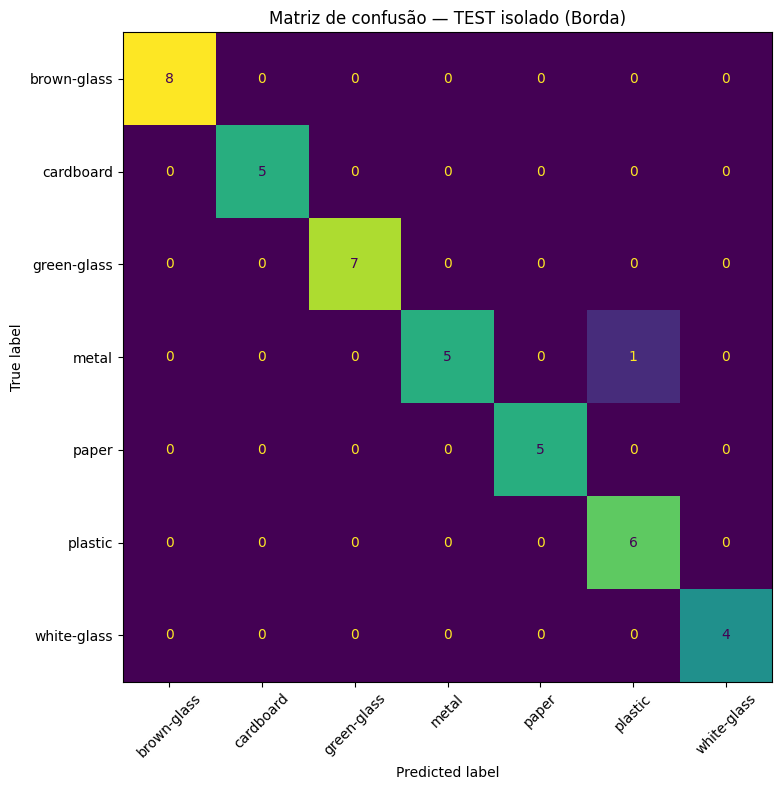


Submatriz dos vidros (linhas=verdade, colunas=previsto):
           white-glass  brown-glass  green-glass
white-glass           4            0            0
brown-glass           0            8            0
green-glass           0            0            7

Confirmação via model.val(split='test'):
Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA A100-SXM4-40GB, 40441MiB)
YOLOv8n-cls summary (fused): 30 layers, 1,443,847 parameters, 0 gradients, 3.3 GFLOPs
train: /content/dataset-ecosort-split/train... found 1050 images in 7 classes ✅ 
val: /content/dataset-ecosort-split/val... found 33 images in 7 classes ✅ 
test: /content/dataset-ecosort-split/test... found 41 images in 7 classes ✅ 
test: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2146.8±644.9 MB/s, size: 131.4 KB)
test: Scanning /content/dataset-ecosort-split/test... 41 images, 0 corrupt: 100% ━━━━━━━━━━━━ 41/41 3.4Kit/s 0.0s
test: New cache created: /content/dataset-ecosort-split/test.cache
               cla

ultralytics.utils.metrics.ClassifyMetrics object with attributes:

confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x790accb3e190>
curves: []
curves_results: []
fitness: 0.9878048896789551
keys: ['metrics/accuracy_top1', 'metrics/accuracy_top5']
results_dict: {'metrics/accuracy_top1': 0.9756097793579102, 'metrics/accuracy_top5': 1.0, 'fitness': 0.9878048896789551}
save_dir: PosixPath('/content/runs/classify/val')
speed: {'preprocess': 0.5854955853636988, 'inference': 4.308517609757008, 'loss': 0.002086146343195074, 'postprocess': 0.0030878536563250236}
top1: 0.9756097793579102
top5: 1.0

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

TEST_DIR = os.path.join(SPLIT_DIR, 'test')
avaliador = YOLO(FINAL_MODEL)
rotulos = sorted(CLASSES_OFICIAIS)

y_true, y_pred = [], []
for c in rotulos:
    pasta = os.path.join(TEST_DIR, c)
    for fn in [f for f in os.listdir(pasta) if not f.startswith('.')]:
        r = avaliador.predict(source=os.path.join(pasta, fn), verbose=False)[0]
        y_true.append(c)
        y_pred.append(r.names[r.probs.top1])

acc = np.mean([t == p for t, p in zip(y_true, y_pred)])
print(f'Acurácia no TEST isolado da Borda: {acc*100:.2f}%  (n={len(y_true)})\n')
print(classification_report(y_true, y_pred, labels=rotulos, zero_division=0))

cm = confusion_matrix(y_true, y_pred, labels=rotulos)
fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay(cm, display_labels=rotulos).plot(ax=ax, xticks_rotation=45, colorbar=False)
ax.set_title('Matriz de confusão — TEST isolado (Borda)')
plt.tight_layout(); plt.show()

vidros = [v for v in ['white-glass', 'brown-glass', 'green-glass'] if v in rotulos]
if len(vidros) >= 2:
    idx = [rotulos.index(v) for v in vidros]
    sub = cm[np.ix_(idx, idx)]
    print('\nSubmatriz dos vidros (linhas=verdade, colunas=previsto):')
    print('           ' + '  '.join(f'{v:>11}' for v in vidros))
    for i, v in enumerate(vidros):
        print(f'{v:>11} ' + '  '.join(f'{sub[i, j]:>11}' for j in range(len(vidros))))

print('\nConfirmação via model.val(split=\'test\'):')
avaliador.val(data=SPLIT_DIR, split='test', imgsz=IMG_SIZE, verbose=False)

## Bloco 9 — Exportar para NCNN + ONNX + Teste de Paridade

Exporta o modelo final (`yolov8n-cls`) tanto para **NCNN** (`best_ncnn_model`) quanto para **ONNX** (`best.onnx`, como backup imediato) e valida a paridade de previsões.

In [ ]:
modelo_final = YOLO(FINAL_MODEL)
ncnn_dir = modelo_final.export(format='ncnn', imgsz=IMG_SIZE)
onnx_path = modelo_final.export(format='onnx', imgsz=IMG_SIZE)
print('Exportado para NCNN:', ncnn_dir)
print('Exportado para ONNX (backup):', onnx_path)

# --- Teste de paridade .pt vs NCNN no TEST isolado ---
modelo_ncnn = YOLO(ncnn_dir, task='classify')
total, iguais, divergencias = 0, 0, []
for c in sorted(CLASSES_OFICIAIS):
    pasta = os.path.join(SPLIT_DIR, 'test', c)
    for fn in [f for f in os.listdir(pasta) if not f.startswith('.')]:
        fp = os.path.join(pasta, fn)
        p_pt   = modelo_final.predict(fp, imgsz=IMG_SIZE, verbose=False)[0]
        p_ncnn = modelo_ncnn.predict(fp, imgsz=IMG_SIZE, verbose=False)[0]
        a, b = p_pt.names[p_pt.probs.top1], p_ncnn.names[p_ncnn.probs.top1]
        total += 1
        if a == b:
            iguais += 1
        else:
            divergencias.append((fn, a, b))

print(f'Paridade .pt x NCNN: {iguais}/{total} previsões iguais')
for fn, a, b in divergencias[:10]:
    print(f'   {fn}: pt={a} | ncnn={b}')
if divergencias:
    print('Há divergências: prefira copiar o best.pt ou best.onnx para a Raspberry Pi.')
else:
    print('NCNN 100% idêntico ao .pt no test! Pronto para copiar para a Raspberry Pi.')

print(f'\nNa borda: copie a pasta {ncnn_dir} (ou o arquivo {FINAL_MODEL}) para ~/ecosort-ai/edge/')

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CPU (Intel Xeon CPU @ 2.20GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLOv8n-cls summary (fused): 30 layers, 1,443,847 parameters, 0 gradients, 0.4 GFLOPs

PyTorch: starting from '/content/drive/MyDrive/EcoSort_Modelos/ecosort_v2_2_0_fase2_borda/weights/best.pt' with input shape (1, 3, 224, 224) BCHW and output shape(s) (1, 7) (2.8 MB)
requirements: Ultralytics requirement ['ncnn'] not found, attempting AutoUpdate...
Using Python 3.13.15 environment at: /usr
Resolved 1 package in 146ms
Prepared 1 package in 348ms
Installed 1 package in 2ms
 + ncnn==1.0.20260526

requirements: AutoUpdate success ✅ 0.8s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect

requirements: Ultralytics requirement ['pnnx==20260526'] not found, attempting AutoUpdate...
Using Python 3.13.15 environment at: /usr
Resolved 30